In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import statistics
import matplotlib.ticker as mticker
from tqdm import tqdm


#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
#CREATE THE MASK

if True:

    # Define the resolution
    lat_resolution = 2.5  # 2.5 degrees
    lon_resolution = 2.5  # 2.5 degrees
    
    # Define the global latitude and longitude ranges
    latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
    longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E
    
    # Initialize a global mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
    lat_min, lat_max = 60, 75
    lon_min, lon_max = -80, -20
    plon = (lon_min+lon_max)/2
    plat = (lat_min+lat_max)/2
    
    # Assign 1 to grid points within the bounding box
    for i, lat in enumerate(latitudes):
        if lat_min <= lat <= lat_max:
            for j, lon in enumerate(longitudes):
                if lon_min <= lon <= lon_max:
                    mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

In [3]:
%cd /Users/michelefilippucci/Data/ERA5
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/Users/michelefilippucci/Data/ERA5
IVT               gr_tracking       sfc_fluxes        winds
cryosphere        precipitation     specific_humidity
geop              scripts           temperature


In [4]:
#IMPORT DATASET
#dic = np.load('gr_tracking/dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy',allow_pickle=True)
ds = xr.load_dataset('gr_tracking/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc')
ds_comp = xr.load_dataset('gr_tracking/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc')
#store variables for the composite
DAV = ds['DAV_tracked']
zg = ds['zg']/9.8
#anom = ds_comp['slhf']*12/86400 - ds_comp['slhf'].mean('time')*12/86400 #converted to KJ
anom = ds_comp['zg']- ds_comp['zg'].mean('time')
lat = ds['lat']
lon = ds['lon']
times = ds['time']

In [5]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in range(n_iter):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

12it [00:43,  3.60s/it]


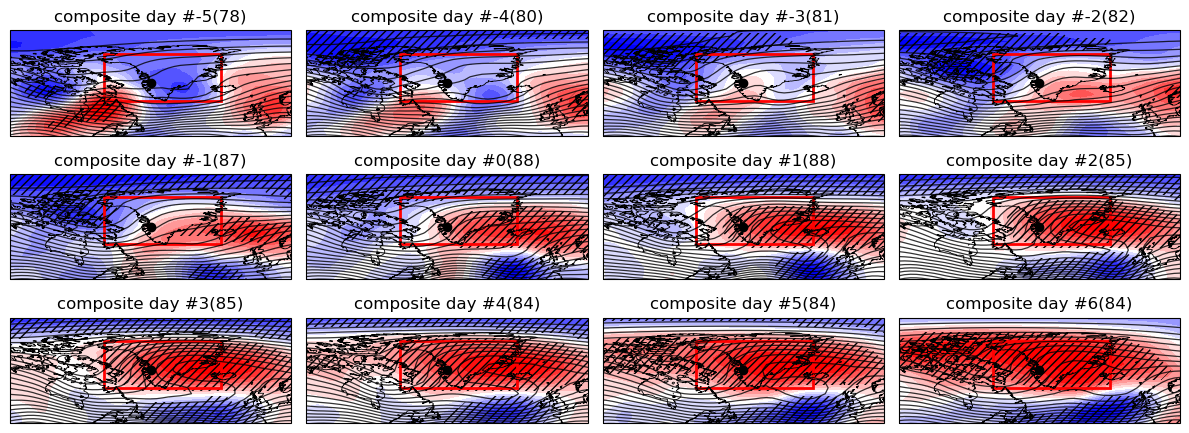

In [7]:
fig, axarr = plt.subplots(nrows=3, ncols=4, figsize=(12,8), subplot_kw={'projection': ccrs.PlateCarree()})
axarr = axarr.flatten()
for i,ax in tqdm(enumerate(axarr[:])):
    if True:
        lat_min, lat_max = 60, 80
        lon_min, lon_max = -70, -20
        # Plot the rectangle
        rect = plt.Rectangle((lon_min, lat_min), lon_max-lon_min, lat_max-lat_min,
                             edgecolor='red', facecolor='none', linewidth=2,
                             transform=ccrs.PlateCarree())
        ax.add_patch(rect)
    #gl.xlabels_top = False
    #gl.ylabels_left = False
    comp_day = i - 5
    domain = DAV.values[:,mask_bool]
    out_of_time_counter = 0
    in_time_counter = 0
    list = []
    list_an = []
    analyzed = []
    #winter
    #list_east = [4, 7, 62, 90, 93, 178, 205, 244, 282, 284, 412, 582, 731, 847, 880, 935, 968, 975, 1017, 1020, 1102, 1153, 1156, 1477, 1584, 1586, 1587, 1622, 1654, 1695, 1698, 1701, 1785, 1830, 1870, 1924, 1927, 2073, 2125, 2165, 2346, 2348, 2437, 2439, 2478, 2481, 2526, 2652, 2654, 2658, 2702, 2741, 2749, 2791, 2881, 2912, 3029, 3033, 3160, 3161, 3207, 3347, 3351, 3432, 3439]
    #list_west = [27, 30, 60, 97, 176, 405, 457, 496, 583, 584, 623, 678, 725, 730, 771, 819, 821, 879, 933, 1021, 1047, 1052, 1053, 1196, 1198, 1200, 1245, 1248, 1249, 1423, 1655, 1657, 1660, 1928, 1972, 1975, 2023, 2522, 2604, 2661, 2841, 2883, 2989, 3162, 3293, 3431, 3521, 3588, 3589, 3590]
    #summer
    list_east = [155, 260, 357, 429, 522, 648, 698, 707, 754, 795, 836, 903, 911, 950, 1076, 1173, 1220, 1226, 1267, 1271, 1353, 1412, 1456, 1508, 1555, 1563, 1637, 1639, 1720, 1723, 1729, 1800, 1802, 1848, 1854, 1896, 1903, 1997, 1998, 2100, 2105, 2107, 2142, 2229, 2230, 2241, 2280, 2326, 2361, 2365, 2377, 2413, 2424, 2459, 2510, 2543, 2593, 2625, 2634, 2684, 2719, 2727, 2758, 2764, 2773, 2813, 2898, 2968, 3007, 3047, 3052, 3135, 3142, 3146, 3189, 3269, 3271, 3312, 3317, 3321, 3376, 3377, 3417, 3457, 3460, 3466, 3536, 3539, 3542, 3625]
    list_west = [44, 74, 302, 309, 353, 477, 517, 597, 660, 905, 1035, 1403, 1409, 1445, 1642, 1724, 1804, 1948, 1956, 2002, 2040, 2232, 2417, 2631, 2680, 2772, 2899, 2929, 3013, 3061, 3180, 3192, 3223, 3231, 3234, 3318, 3322, 3369, 3468, 3570, 3577, 3621]
    for t,time in enumerate(times):
        idxs = np.unique(domain[t,:])
        for i in idxs:
            if i in list_east and not i in analyzed:#in list_west:
                analyzed.append(i)
                try:
                    list.append(zg.loc[time + np.timedelta64(comp_day,'D'),:,:].values)
                    list_an.append(anom.loc[time + np.timedelta64(comp_day,'D'),:,:].values)
                    in_time_counter += 1
                except:
                    out_of_time_counter += 1
    sum_t = sum(list)
    sum_an = sum(list_an)
    zg_comp = sum_t/len(list)
    anom_comp = -np.mean(anom,axis=0) + sum_an/len(list_an)
    t_st_anom = abs(anom_comp/Bootstrap(anom,len(list_an),1000)) > 2

    title = ''
    field = ma.masked_array(zg_comp,zg_comp==0)
    extent =[-110,10,45,90] #Greenland
    ax.set_extent(extent, ccrs.PlateCarree())
    ax.coastlines(linewidth = 0.6)
    ax.plot(plon,plat,color='black', marker='o')
    '''
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                    linewidth=1, 
                    color='gray', 
                    alpha=0.5, 
                    linestyle='--')
    '''
    cont = ax.contour(lon,lat,field,
                        colors = 'black',
                        alpha =0.8,
                        linewidths = 0.9,
                        levels = np.arange(4600,7200,20)
                        )
                        #cmap = "YlGnBu")
    c_range = np.array(np.arange(-np.amax(abs(anom_comp)), +np.amax(abs(anom_comp)), np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
    #c_range = np.arange(-32.5, 33, 5)
    ticks = np.array(np.arange(-np.amax(abs(anom_comp)), +np.amax(abs(anom_comp)), np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
    #ticks = np.arange(-30, 31, 10)
    shadings = ax.contourf(lon,lat,anom_comp,
                          cmap='bwr',
                          extend = 'both', 
                          levels = c_range)
    
    cs_p = ax.contourf(lon,lat,t_st_anom,levels = 1,colors='none',hatches=['','////'])

    #fig.colorbar(shadings,ticks=ticks,label='temperature (K)',orientation='horizontal',shrink=0.5,ax=ax)
    ax.set_title('composite day #' + str(comp_day) + '('+ str(in_time_counter) + ')')
    plt.tight_layout()
    #plt.savefig('/Users/michelefilippucci/PLOTS/EGU/gif_west/composite_greenland_from_west_'+str(comp_day)+'.png',dpi=300)
